# Logistics Delivery Risk Intelligence

**Author:**Niharika N K

## Objective

The objective of this analysis is to evaluate the Routewise shipments for planner intervention:

1. Forcasting hours of delay we can expect for that partcular shipment
2. Predicting wheather the product shipment has to be marked as delay risk 
3. Discovering operating patterns across the networkand which one carry most risk using clustering.

# Task 1 : Shipment data Understanding and Validation


In [7]:
import pandas as pd
import numpy as np

shipment_data_df = pd.read_csv(r"D:\Projects\Logistics Delivery Risk Intelligence\data\logistics_delivery_delay (1).csv")
print(f"Imported records count{ shipment_data_df.shape}")
print(f"Total columns count is: { shipment_data_df.shape[1]} \n and verifying its data types{shipment_data_df.info()}")

Imported records count(720, 17)
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   shipment_timestamp          720 non-null    str    
 1   origin_hub                  720 non-null    str    
 2   destination_type            720 non-null    str    
 3   shipping_mode               720 non-null    str    
 4   carrier                     720 non-null    str    
 5   distance_km                 720 non-null    float64
 6   package_weight_kg           719 non-null    float64
 7   weather_condition           719 non-null    str    
 8   traffic_level               719 non-null    str    
 9   carrier_rating              719 non-null    float64
 10  warehouse_processing_hours  719 non-null    float64
 11  dispatch_delay_hours        720 non-null    float64
 12  handling_time_hours         720 non-null    float64
 13  expected_deliv

In [23]:
#Time coverage of the shipment data 
#Change the datatype of timestamp

shipment_data_df['shipment_timestamp'] = pd.to_datetime(shipment_data_df['shipment_timestamp'],errors= 'coerce')
print(f"To analyse, Shipment data is available from { shipment_data_df['shipment_timestamp'] .min() } to {shipment_data_df['shipment_timestamp'] .max()}")

#Distribution of every categorical column 
print("Distribution of data")
[print(f" {col} : {shipment_data_df[col].value_counts()}") 
 for col in shipment_data_df.select_dtypes(include='string').columns  
 ]


To analyse, Shipment data is available from 2026-04-01 06:00:00 to 2026-06-30 03:00:00
Distribution of data
 origin_hub : origin_hub
North Hub    180
South Hub    180
East Hub     180
West Hub     180
Name: count, dtype: int64
 destination_type : destination_type
Metro          180
Industrial     180
Rural          180
Tier-2 City    180
Name: count, dtype: int64
 shipping_mode : shipping_mode
Road    240
Rail    240
Air     240
Name: count, dtype: int64
 carrier : carrier
Carrier-A    180
Carrier-D    180
Carrier-C    180
Carrier-B    180
Name: count, dtype: int64
 weather_condition : weather_condition
Clear     180
Storm     180
Cloudy    180
Rain      179
Name: count, dtype: int64
 traffic_level : traffic_level
High      359
Low       180
Medium    180
Name: count, dtype: int64


[None, None, None, None, None, None]

#Summary statistics and Target analysis
## 1.6 Target Variable analysis 

it has two targets 
regression target : delivery delay hours

Classification target : delay required

In [25]:
print(
    f"Logistics Delivery classification target distribution:\n"
    f"{shipment_data_df['delay_required'].value_counts(normalize=True)}\n"
    f"Percentage of Logistics Delivery classification target: {(shipment_data_df['delay_required'].value_counts(normalize=True) * 100).round(2)}%\n"
   f"Regression target summary:\n{shipment_data_df['delivery_delay_hours'].describe()}"
)

Logistics Delivery classification target distribution:
delay_required
1    0.693056
0    0.306944
Name: proportion, dtype: float64
Percentage of Logistics Delivery classification target: delay_required
1    69.31
0    30.69
Name: proportion, dtype: float64%
Regression target summary:
count    720.000000
mean       4.591972
std        2.611877
min        0.000000
25%        2.397500
50%        5.125000
75%        6.632500
max       10.440000
Name: delivery_delay_hours, dtype: float64


**2. Classification target — Delay Required**

The classification target is imbalanced, with the `Delay Required` class accounting for approximately 30% of observations. This indicates that Delay-required events occur less frequently than the other class or classes. Model evaluation should therefore consider precision, recall, F1-score, and the confusion matrix rather than relying solely on accuracy.

In [28]:
## 1.4 Missing Values Analysis
# to avoid missing values affecting the model quality.

print(f"Logistics Delivery Risk DataFrame missing values:\n{shipment_data_df.isnull().sum()}")

for col in shipment_data_df.columns:
    missing_percentage = shipment_data_df[col].isnull().mean() * 100
    if missing_percentage > 0:
     print(f"Column '{col}' has {missing_percentage:.2f}% missing values.\n")
     #check the rows with missing values and its associated delay.
     print(f"\n #Only a small number of missing values were identified in : package_weight_kg  , weather_condition, traffic_level,carrier_rating and warehouse_processing_hours.")
     print(f"\nTo handle since its very few , we shall verify which sale events its triggering ")
    if shipment_data_df[col].isnull().any():
       missing_rows = shipment_data_df[shipment_data_df[col].isnull()]
       print(f"Rows with missing values in column '{col}':\n{missing_rows[['delay_required', col]]}\n")
        

Logistics Delivery Risk DataFrame missing values:
shipment_timestamp            0
origin_hub                    0
destination_type              0
shipping_mode                 0
carrier                       0
distance_km                   0
package_weight_kg             1
weather_condition             1
traffic_level                 1
carrier_rating                1
warehouse_processing_hours    1
dispatch_delay_hours          0
handling_time_hours           0
expected_delivery_hours       0
actual_delivery_hours         0
delivery_delay_hours          0
delay_required                0
dtype: int64
Column 'package_weight_kg' has 0.14% missing values.


 #Only a small number of missing values were identified in : package_weight_kg  , weather_condition, traffic_level,carrier_rating and warehouse_processing_hours.

To handle since its very few , we shall verify which sale events its triggering 
Rows with missing values in column 'package_weight_kg':
     delay_required  package_weight_kg

## 1.5 Unusual and Extreme Observations




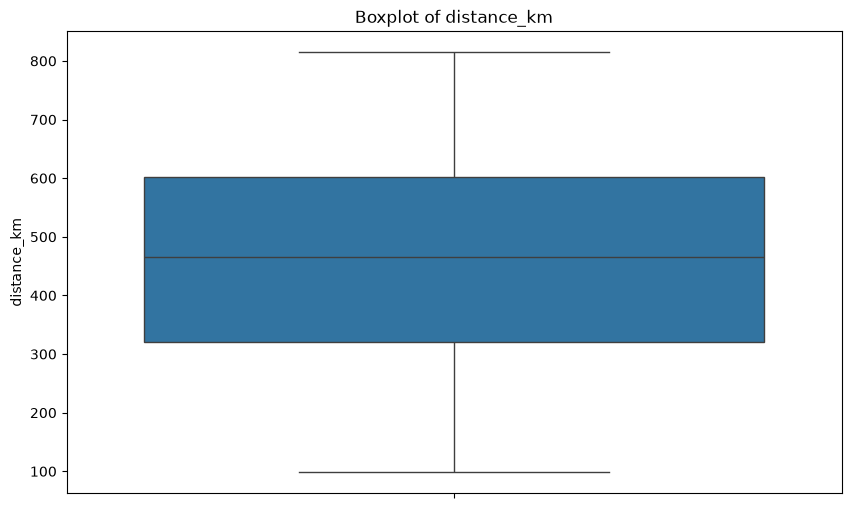

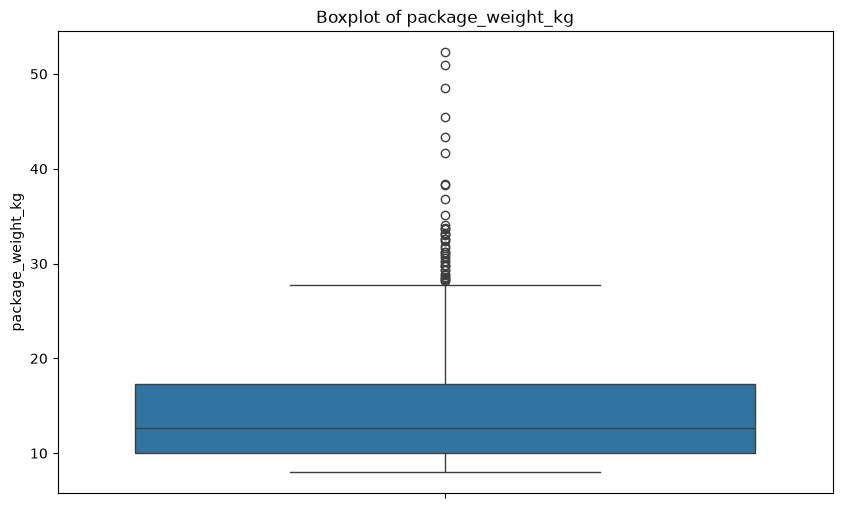

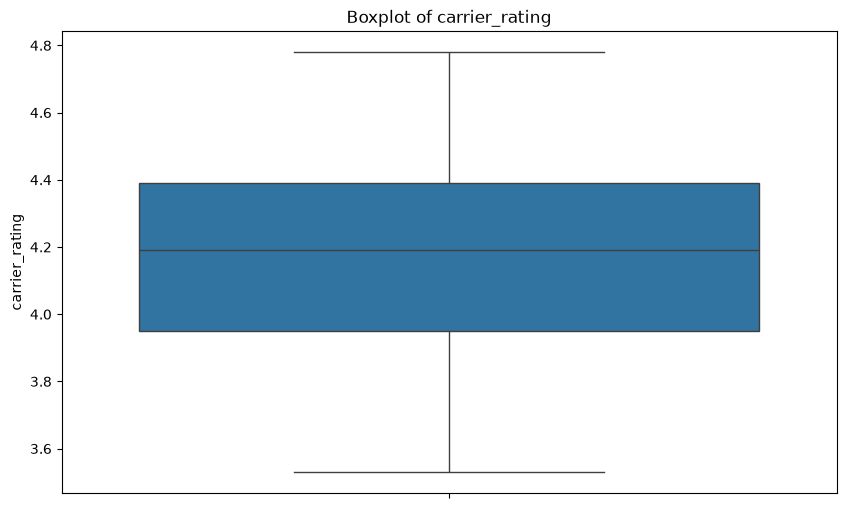

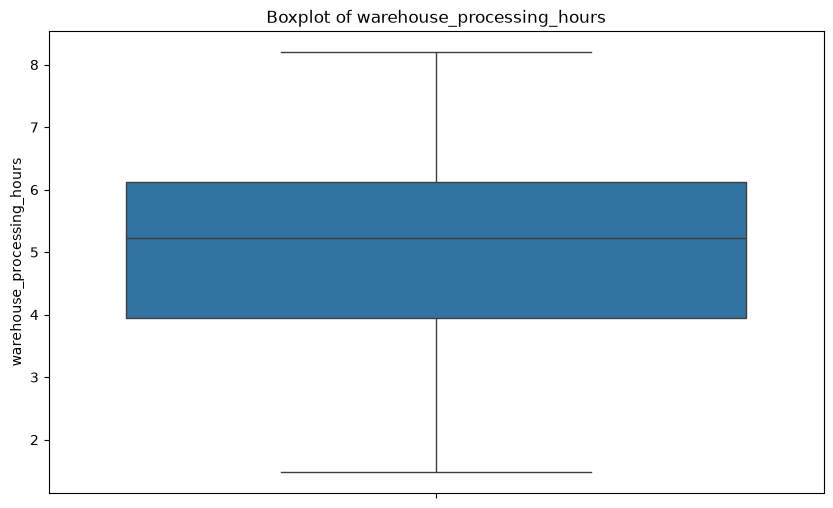

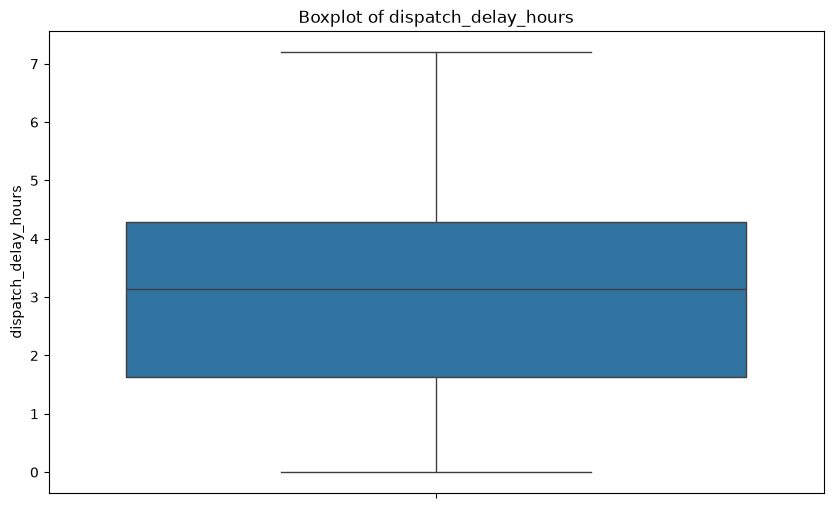

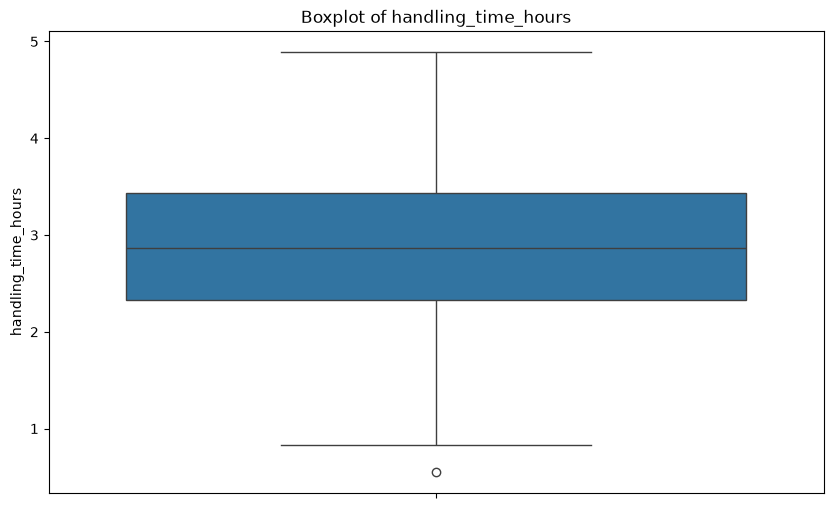

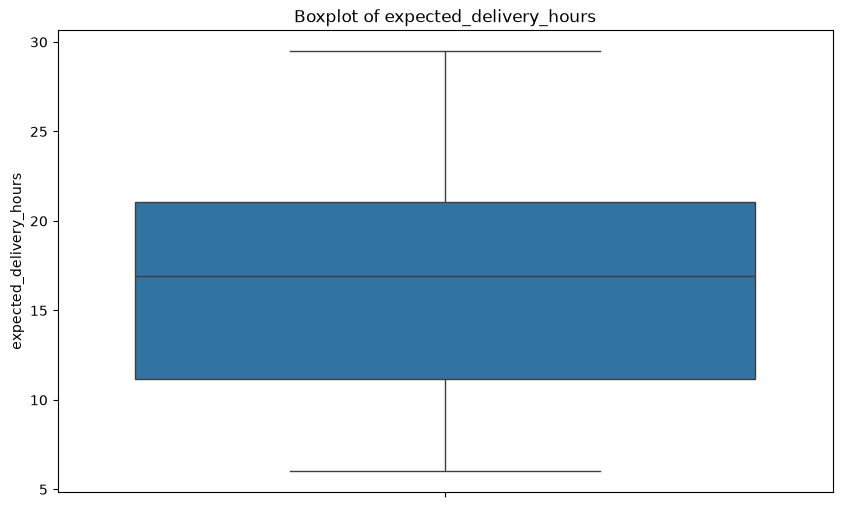

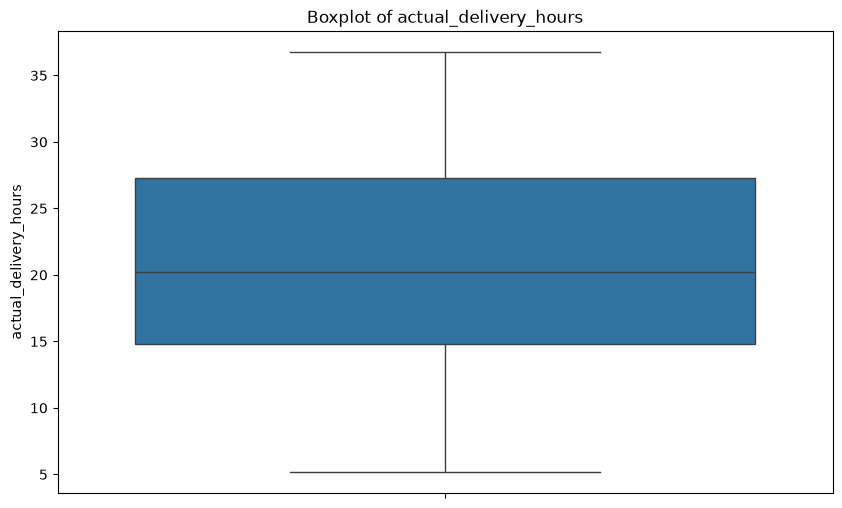

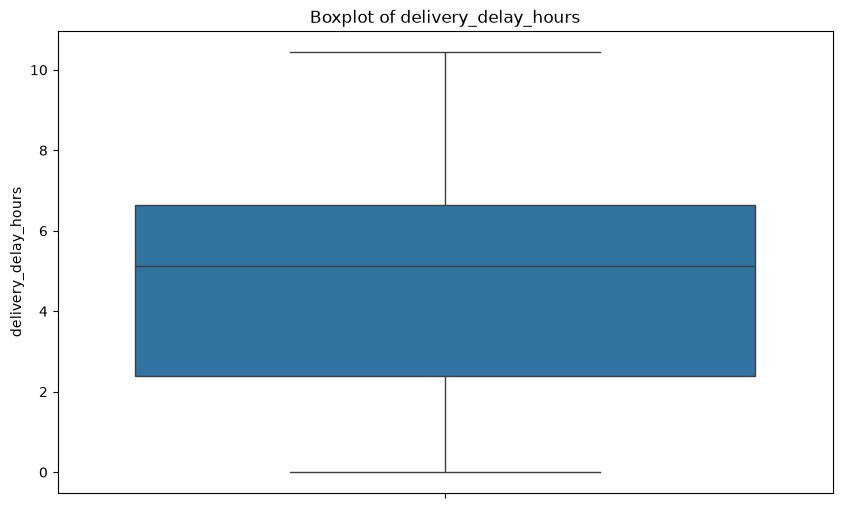

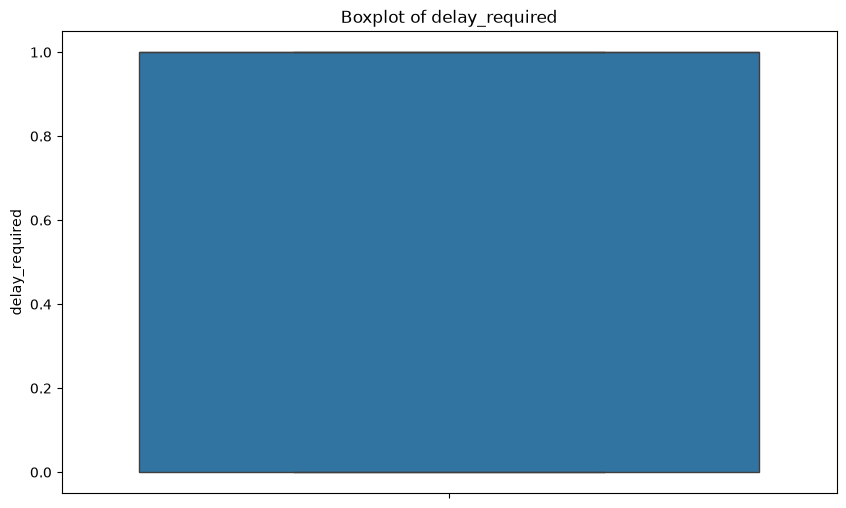

In [33]:
import seaborn as sns
import matplotlib.pyplot as plt

for col in shipment_data_df.columns:
    if shipment_data_df[col].dtype in [np.float64, np.int64]:
        plt.figure(figsize=(10, 6))
        sns.boxplot(shipment_data_df[col])
        plt.title(f'Boxplot of {col}')
        plt.savefig(r'D:\Projects\Logistics Delivery Risk Intelligence\outputs\tasks1\boxplot_{col}.png')
        plt.show()
             

In [ ]:
#Observing delay required behaviour across shipping mode, traffic level, weather condition, destination type and carrier 

categorical_col = [
    'shipping_mode',
    'traffic_level', 
    'weather_condition', 
     'destination_type',
      'carrier'

]

for col in categorical_col:
     comparision_df = shipment_data_df.groupby([col,'delay_required']).size().unstack(fill_value=0)
     print(f"\nComparison: {col} vs delay_required")
     print(f"{comparision_df}")
          


Comparison: shipping_mode vs delay_required
delay_required   0    1
shipping_mode          
Air             74  166
Rail            71  169
Road            76  164

Comparison: traffic_level vs delay_required
delay_required    0    1
traffic_level           
High             43  316
Low             177    3
Medium            1  179

Comparison: weather_condition vs delay_required
delay_required       0    1
weather_condition          
Clear              177    3
Cloudy              36  144
Rain                 7  172
Storm                1  179

Comparison: destination_type vs delay_required
delay_required      0    1
destination_type          
Industrial          1  179
Metro             177    3
Rural               7  173
Tier-2 City        36  144

Comparison: carrier vs delay_required
delay_required    0    1
carrier                 
Carrier-A       177    3
Carrier-B        36  144
Carrier-C         7  173
Carrier-D         1  179


# Task 2: Data Preparation for ML

## Purpose : Data must be transformed into a machine learning ready dataset 

In [77]:
shipment_data_df_copy = shipment_data_df.copy()

#Timestamp cpnve

shipment_data_df_copy['day_of_the_week'] = shipment_data_df_copy['shipment_timestamp'].dt.day_of_week
shipment_data_df_copy['hour_of_the_day'] = shipment_data_df_copy['shipment_timestamp'].dt.hour



# Missing values 

# Why Median to handle missing values

A distribution can look fairly symmetric overall but contain a few extreme observations.It is less sensitive to unusually large or small values.
categorical variables were imputed using the mode to preserve the existing category distribution while minimizing distortion of the dataset

In [90]:
#Missing value treatment

for col in shipment_data_df_copy.columns:
    if (shipment_data_df_copy[col].isnull().any()) and pd.api.types.is_numeric_dtype(shipment_data_df_copy[col]):
        
        print(f"Missing values before dropping {col}:\n{shipment_data_df_copy[col].isnull().sum()}")
        
        shipment_data_df_copy[col] = shipment_data_df_copy[col].fillna(shipment_data_df_copy[col].median())

        print(f"Missing values after filling {col}:\n{shipment_data_df_copy[col].isnull().sum()}")
    elif (shipment_data_df_copy[col].isna().any()) and pd.api.types.is_string_dtype(shipment_data_df_copy[col]):
        print(f"Missing values before dropping {col}:\n{shipment_data_df_copy[col].isna().sum()}")
        
        shipment_data_df_copy[col] = shipment_data_df_copy[col].fillna(shipment_data_df_copy[col].mode()[0])

        print(f"Missing values after filling {col}:\n{shipment_data_df_copy[col].isna().sum()}")
        

# Encode categories 

## Using One-Hot for 'origin_hub','destination_type','shipping_mode','carrier','weather_condition'

## Using Ordinal for Traffic Level

Ordinal encoding was chosen for traffic_level because its categories (Low, Medium, High) have a natural order representing increasing traffic severity. Unlike one-hot encoding, it preserves this ordinal relationship while keeping the number of features unchanged, making it a suitable choice for this feature.

In [78]:
# One Hot encoding 

categorical_encode_one_hot = ['origin_hub','destination_type','shipping_mode','carrier','weather_condition']
shipment_data_encoded = pd.get_dummies(shipment_data_df_copy,columns=categorical_encode_one_hot,drop_first=True)
encoded_col = []
for original_col in categorical_encode_one_hot :
    for col in shipment_data_encoded.columns:
        if col.startswith(f"{original_col}_"):  
           encoded_col.append(col)

for col in encoded_col:
   print(f"Encoded columns for '{col}'")
   print(f"{shipment_data_encoded[col].head(5)}")


   

Encoded columns for 'origin_hub_North Hub'
0     True
1    False
2    False
3    False
4     True
Name: origin_hub_North Hub, dtype: bool
Encoded columns for 'origin_hub_South Hub'
0    False
1     True
2    False
3    False
4    False
Name: origin_hub_South Hub, dtype: bool
Encoded columns for 'origin_hub_West Hub'
0    False
1    False
2    False
3     True
4    False
Name: origin_hub_West Hub, dtype: bool
Encoded columns for 'destination_type_Metro'
0     True
1    False
2    False
3    False
4     True
Name: destination_type_Metro, dtype: bool
Encoded columns for 'destination_type_Rural'
0    False
1    False
2     True
3    False
4    False
Name: destination_type_Rural, dtype: bool
Encoded columns for 'destination_type_Tier-2 City'
0    False
1    False
2    False
3     True
4    False
Name: destination_type_Tier-2 City, dtype: bool
Encoded columns for 'shipping_mode_Rail'
0    False
1     True
2    False
3    False
4     True
Name: shipping_mode_Rail, dtype: bool
Encoded columns 

In [ ]:
# Ordinal Encoding

from sklearn.preprocessing import OrdinalEncoder

encoder = OrdinalEncoder(
    categories= [['Low','Medium','High']]
)

shipment_data_df_copy['traffic_level_encoded'] = encoder.fit_transform(shipment_data_df_copy[['traffic_level']] ).ravel()


#Scaling will be done while training LR model

# Inspect Outliers

In [95]:
outlier_summary = [  ]
for col in shipment_data_df_copy.columns:
    if pd.api.types.is_numeric_dtype(shipment_data_df_copy[col]):
     Q1 = shipment_data_df_copy[col].quantile(0.25)
     Q3 = shipment_data_df_copy[col].quantile(0.75)

     IQR = Q3 - Q1

     lower_bound = Q1 - 1.5 * IQR
     upper_bound = Q3 + 1.5 * IQR

     outliers = shipment_data_df_copy[
                     (shipment_data_df_copy[col]< lower_bound)|
                     (shipment_data_df_copy[col]> upper_bound)

     ].shape[0]
     max = shipment_data_df_copy[col].max()
     outlier_summary.append((Q1,Q3,IQR,col,outliers,max))

     pd.DataFrame(
        outlier_summary,columns=['Q1','Q3','IQR','col','outlier_count','max']
     )
print(f"Outlier summary:\n{pd.DataFrame(outlier_summary, columns=['Q1', 'Q3', 'IQR', 'col', 'outlier_count','max'])}")


Outlier summary:
          Q1        Q3       IQR                         col  outlier_count  \
0   320.4250  602.6750  282.2500                 distance_km              0   
1    10.0000   17.2250    7.2250           package_weight_kg             41   
2     3.9500    4.3900    0.4400              carrier_rating              0   
3     3.9400    6.1300    2.1900  warehouse_processing_hours              0   
4     1.6275    4.2800    2.6525        dispatch_delay_hours              0   
5     2.3300    3.4325    1.1025         handling_time_hours              1   
6    11.1600   21.0575    9.8975     expected_delivery_hours              0   
7    14.8175   27.2625   12.4450       actual_delivery_hours              0   
8     2.3975    6.6325    4.2350        delivery_delay_hours              0   
9     0.0000    1.0000    1.0000              delay_required              0   
10    1.0000    5.0000    4.0000             day_of_the_week              0   
11    5.2500   15.7500   10.5000   

### Outlier Detection Using the IQR Method — Observations

The Interquartile Range (IQR) method was used to identify potential outliers in the numerical features of the Logistics Delivery Risk dataset.

- **Package weight:** `package_weight_kg` contains 41 potential outliers, with Q1 = 10.00 kg, Q3 = 17.225 kg, and IQR = 7.225 kg. The maximum observed weight is 52.30 kg, indicating that some shipments have considerably higher weights than the central 50% of the data.
- **Handling time:** `handling_time_hours` contains only one potential outlier, suggesting that extreme values are uncommon in this feature.
- **Other numerical features:** No outliers were detected in the remaining features using the IQR method.

**Conclusion and action:** Package weight requires further investigation to determine whether the extreme values represent valid heavy shipments or data-entry errors. These observations should not be removed automatically, as high-weight shipments may reflect genuine operational conditions. The single handling-time outlier should also be reviewed. Any treatment, such as correction, capping, or retention, should be based on domain knowledge and its potential impact on model performance.

In [98]:
#target columns are seperated
y_reg = shipment_data_df_copy['delivery_delay_hours']
y_cls = shipment_data_df_copy['delay_required']

X = shipment_data_df_copy.drop(columns=['delivery_delay_hours','delay_required'])


# Task 3: Feature Engineering ans Selection 